In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
import os
from sklearn.metrics import r2_score
from sklearn.feature_extraction.text import TfidfVectorizer

In [2]:
folder=os.listdir('data')
train_file=folder[1]
test_file=folder[0]
val_file=folder[2]


In [3]:
def load_data(file_path):
    with open(os.path.join('data',file_path),'r') as f:
        data=pd.read_csv(f)
    return data

In [4]:
data_train=load_data(train_file)
data_test=load_data(test_file)
data_val=load_data(val_file)

data_train['Review'].head()

0    nice hotel expensive parking got good deal sta...
1    ok nothing special charge diamond member hilto...
2    nice rooms not 4* experience hotel monaco seat...
3    unique, great stay, wonderful time hotel monac...
4    great stay great stay, went seahawk game aweso...
Name: Review, dtype: object

In [5]:
vectorize=TfidfVectorizer(ngram_range=(1,4),max_features=20000)

def vectorize_data(data,colone_name,type=''):
    
    if type.lower()=='train':
        return vectorize.fit_transform(data[colone_name])
    if type.lower()=='test' or type.lower()=='val':
        return vectorize.transform(data[colone_name])


In [6]:
data_train_vec=vectorize_data(data_train,'Review','train')

data_train_vec_rating=data_train['Rating']


data_train_vec[2,:10].todense()
data_train_vec_rating=torch.tensor(data_train_vec_rating)

In [7]:
class RegressionModel(nn.Module):
    def __init__(self,input_dim):
        super().__init__()
        self.model=nn.Sequential(
            nn.Linear(input_dim,256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.9),
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Dropout(0.8),
            nn.Linear(64,1)
         
            )



    def forward(self,x):
        return self.model(x)


In [8]:
row,dim=data_train_vec.shape

In [9]:
row,dim

(18491, 20000)

In [10]:
data_val_vec=vectorize_data(data_val,'Review','val')
data_val_rating_vec=torch.tensor(data_val['Rating'])

In [11]:
#train info
batch_size = 256
n_samples = data_train_vec.shape[0]
all_train_error=[]
epochs=32
learning_error=0
device='cuda' if torch.cuda.is_available() else 'cpu'
#val info
n_samples_val=data_val_vec.shape[0]
total_val_error=0
all_val_error=[]
batch_val_size=256
val_error=0

#model
model=RegressionModel(dim).to(device)
optimizer=torch.optim.Adam(model.parameters(),lr=0.00002)
loss_function=nn.MSELoss()
model.train()

for epoch in range(epochs):
    total_loss = 0
    for start in range(0, n_samples, batch_size):
        end = start + batch_size
        
        # Get batches for both X and Y simultaneously
        X_batch = torch.tensor(data_train_vec[start:end].todense(), dtype=torch.float32).to(device)
        Y_batch = torch.tensor(data_train_vec_rating[start:end], dtype=torch.float32).view(-1, 1).to(device)

        # Forward pass
        y_pred = model(X_batch)
        loss = loss_function(y_pred, Y_batch)
        
        # Backward pass (Optimization)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    loss_error=total_loss/(n_samples/batch_size)
    learning_error+=loss_error
    all_train_error.append(loss_error)

    model.eval()
    total_val_error=0
    with torch.no_grad():
        for start in range(0,n_samples_val,batch_val_size):
            end=start + batch_val_size
            X_val_batch=torch.tensor(data_val_vec[start:end].todense(),dtype=torch.float32).to(device)
            Y_val_batch=torch.tensor(data_val_rating_vec[start:end],dtype=torch.float32).view(-1,1).to(device)

            y_val_pred=model(X_val_batch)

            loss=loss_function(y_val_pred,Y_val_batch)
            total_val_error+=loss.item()
        loss_val_error=total_val_error/(n_samples_val/batch_val_size)
        val_error+=loss_val_error
        all_val_error.append(loss_val_error)
    print(f"Val error {loss_val_error:.4f}")

    
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss_error:.4f}")
print(f"Learning Error {learning_error/epochs}")

AcceleratorError: CUDA error: out of memory
Search for `cudaErrorMemoryAllocation' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


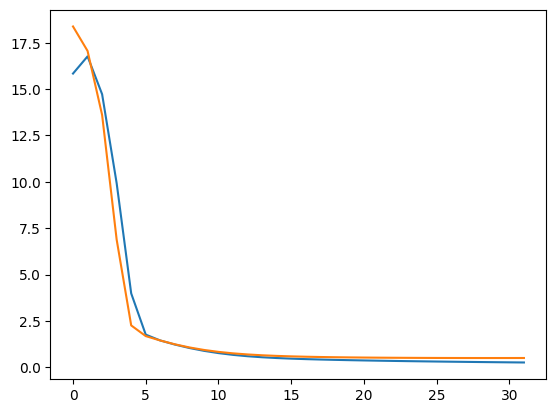

In [ ]:
x=[i for i in range(epochs)]
y=all_train_error
z=all_val_error
plt.plot(x,y)
plt.plot(x,z)

In [ ]:
torch.round(y_pred)==Y_batch

tensor([[ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [False],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [False],
        [ True],
        [ True],
        [ True],
        [False],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True

In [ ]:
data_test_vec=vectorize_data(data_test,'Review','test')
data_test_vec_rating=data_test['Rating']
y_test=torch.tensor(data_test_vec_rating)
data_test_vec

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 106743 stored elements and shape (1000, 15000)>

In [ ]:
model.eval()
batch_test_size=32
n_samples_test=data_test_vec.shape[0]
total_test_loss=0


with torch.no_grad():

    for start in range(0,n_samples_test,batch_test_size):
        end = start + batch_test_size
        x_batch_test=torch.tensor(data_test_vec[start:end].todense(),dtype=torch.float32).to(device)
        y_batch_test=torch.tensor(y_test[start:end],dtype=torch.float32).view(-1,1).to(device)


        y_test_pred=model(x_batch_test)
        loss=loss_function(y_test_pred,y_batch_test)
        total_test_loss+=loss.item()
        r2_loss=r2_score(y_batch_test.to('cpu'),y_test_pred.to('cpu'))
     

print(f"Test Error: {total_test_loss/(n_samples_test/batch_test_size):.4f}")
print(f"Performance model : {r2_loss}")

Test Error: 0.4684
Performance model : 0.6463174819946289


/tmp/ipykernel_8678/2828210933.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_batch_test=torch.tensor(y_test[start:end],dtype=torch.float32).view(-1,1).to(device)
/tmp/ipykernel_8678/2828210933.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_batch_test=torch.tensor(y_test[start:end],dtype=torch.float32).view(-1,1).to(device)
/tmp/ipykernel_8678/2828210933.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_batch_test=torch.tensor(y_test[start:end],dtype=torch.float32).view(-1,1).to(device)
/tmp/ipykernel_8678/2828210933.

In [ ]:
model.eval()
all_preds = []
all_true = []

with torch.no_grad():
    for start in range(0, n_samples_test, batch_test_size):
        end = start + batch_test_size
        x_batch_test = torch.tensor(data_test_vec[start:end].todense(), dtype=torch.float32).to(device)
        y_batch_test = torch.tensor(y_test[start:end], dtype=torch.float32).view(-1, 1)

        y_test_pred = model(x_batch_test)
        
        all_preds.extend(y_test_pred.cpu().numpy())
        all_true.extend(y_batch_test.numpy())

final_r2 = r2_score(all_true, all_preds)
print(f"Performance globale sur tout le test : {final_r2:.4f}")

Performance globale sur tout le test : 0.6783


/tmp/ipykernel_8678/38380720.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_batch_test = torch.tensor(y_test[start:end], dtype=torch.float32).view(-1, 1)


In [ ]:
#torch.save(model.state_dict(),'model_v1/model_v5.pth')

In [ ]:
print(f"Mémoire allouée: {torch.cuda.memory_allocated() / 1024**2:.2f} MB")
print(f"Mémoire réservée: {torch.cuda.memory_reserved() / 1024**2:.2f} MB")


Mémoire allouée: 93.99 MB
Mémoire réservée: 584.00 MB


In [ ]:
correct=0
error=0
result=torch.round(y_test_pred.cpu())==y_batch_test
print(result.shape)
for i in result:
    if i==True:
        correct+=1
    else:
        error+=1
print(f"Correct: {correct}  Error: {error}" )
success_rate=correct*100/result.shape[0]
print(f"Taux de reussite {success_rate:.2f}%")


torch.Size([8, 1])
Correct: 3  Error: 5
Taux de reussite 37.50%
